# Time Calibration
Using data from first calibration campaign on 2025/09/17

In [161]:
from pathlib import Path
from padre_meddea.io import read_file
from astropy.table import vstack
from padre_meddea.housekeeping.calibration import calibrate_hk_ts
import matplotlib.pyplot as plt
import numpy as np
from astropy.time import TimeDelta
from astropy.timeseries import TimeSeries
import astropy.units as u
from astropy.table import QTable

In [6]:
files = list(Path(r'C:\Users\sdchris1\OneDrive - NASA\Desktop\data\meddea').glob('padreMDU8_250917*.dat'))
files

[WindowsPath('C:/Users/sdchris1/OneDrive - NASA/Desktop/data/meddea/padreMDU8_250917042330.dat'),
 WindowsPath('C:/Users/sdchris1/OneDrive - NASA/Desktop/data/meddea/padreMDU8_250917060741.dat'),
 WindowsPath('C:/Users/sdchris1/OneDrive - NASA/Desktop/data/meddea/padreMDU8_250917074131.dat'),
 WindowsPath('C:/Users/sdchris1/OneDrive - NASA/Desktop/data/meddea/padreMDU8_250917092240.dat'),
 WindowsPath('C:/Users/sdchris1/OneDrive - NASA/Desktop/data/meddea/padreMDU8_250917105030.dat')]

In [17]:
hk_ts, cmd_ts = read_file(files[0])
for this_file in files[1:-1]:
    nhk_ts, ncmd_ts = read_file(this_file)
    hk_ts = vstack([hk_ts, nhk_ts])
    cmd_ts = vstack([cmd_ts, ncmd_ts])
hk_ts = calibrate_hk_ts(hk_ts)

2025-11-20 15:03:35 - swxsoc - INFO: padreMDU8_250917042330.dat: Found housekeeping data
2025-11-20 15:03:35 - swxsoc - INFO: padreMDU8_250917042330.dat: Found read data
2025-11-20 15:03:35 - swxsoc - INFO: padreMDU8_250917060741.dat: Found housekeeping data


INFO: padreMDU8_250917042330.dat: Found housekeeping data [padre_meddea.housekeeping.housekeeping]
INFO: padreMDU8_250917042330.dat: Found read data [padre_meddea.housekeeping.housekeeping]
INFO: padreMDU8_250917060741.dat: Found housekeeping data [padre_meddea.housekeeping.housekeeping]


2025-11-20 15:03:35 - swxsoc - INFO: padreMDU8_250917060741.dat: Found read data
2025-11-20 15:03:35 - astropy - WARNING: MergeConflictWarning: Cannot merge meta key 'ORIGFILE' types <class 'str'> and <class 'str'>, choosing ORIGFILE='padreMDU8_250917060741.dat'
2025-11-20 15:03:35 - swxsoc - INFO: padreMDU8_250917074131.dat: Found housekeeping data
2025-11-20 15:03:36 - swxsoc - INFO: padreMDU8_250917074131.dat: Found read data
2025-11-20 15:03:36 - astropy - WARNING: MergeConflictWarning: Cannot merge meta key 'ORIGFILE' types <class 'str'> and <class 'str'>, choosing ORIGFILE='padreMDU8_250917074131.dat'
2025-11-20 15:03:36 - swxsoc - INFO: padreMDU8_250917092240.dat: Found housekeeping data


INFO: padreMDU8_250917060741.dat: Found read data [padre_meddea.housekeeping.housekeeping]
INFO: padreMDU8_250917074131.dat: Found housekeeping data [padre_meddea.housekeeping.housekeeping]
INFO: padreMDU8_250917074131.dat: Found read data [padre_meddea.housekeeping.housekeeping]
INFO: padreMDU8_250917092240.dat: Found housekeeping data [padre_meddea.housekeeping.housekeeping]


2025-11-20 15:03:36 - swxsoc - INFO: padreMDU8_250917092240.dat: Found read data
2025-11-20 15:03:36 - astropy - WARNING: MergeConflictWarning: Cannot merge meta key 'ORIGFILE' types <class 'str'> and <class 'str'>, choosing ORIGFILE='padreMDU8_250917092240.dat'


INFO: padreMDU8_250917092240.dat: Found read data [padre_meddea.housekeeping.housekeeping]


In [13]:
cmd_ts

time,pkttimes,pktclock,address,value,seqcount,name
Time,uint32,uint32,uint16,uint16,uint16,str25
2025-09-17 04:59:55.306,811400400,6123413,1032,17,0,time_core_status
2025-09-17 05:00:55.421,811400460,8421508,1034,12,1,time_intvector
2025-09-17 05:01:55.488,811400520,9759121,1040,11796,2,time_last_offset0_least
2025-09-17 05:02:55.056,811400580,1119826,1042,305,3,time_last_offset0_most
2025-09-17 05:03:55.147,811400640,2943074,1044,11794,4,time_pps_count0_least
2025-09-17 05:04:55.201,811400700,4013683,1046,305,5,time_pps_count0_most
2025-09-17 05:05:55.277,811400760,5537659,1072,11792,6,time_last1sec_count_least
2025-09-17 05:06:55.212,811400820,4230095,1074,305,7,time_last1sec_count_most
2025-09-17 06:08:05.257,811404490,5135485,1032,17,0,time_core_status


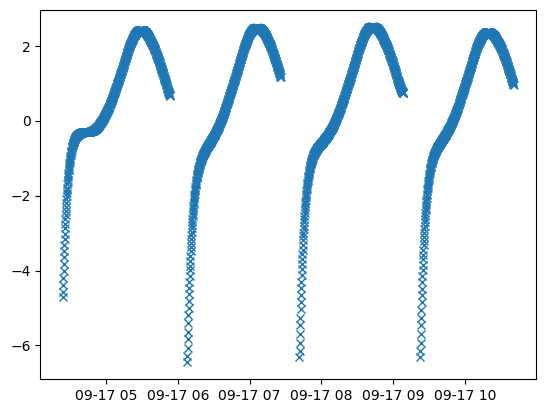

In [23]:
plt.plot(hk_ts.time.to_datetime(), hk_ts['dib_temp'], 'x')

In [29]:
np.unique(cmd_ts['name'])

time_core_status
time_intvector
time_last1sec_count_least
time_last1sec_count_most
time_last_offset0_least
time_last_offset0_most
time_pps_count0_least
time_pps_count0_most


time_last1sec_count_least, time_last_offset0_least, time_pps_count0_least should all be reading the number of clock ticks between each PPS if we are NOT freewheeling

In [25]:
ind = cmd_ts['name'] == 'time_intvector'
cmd_ts[ind]

time,pkttimes,pktclock,address,value,seqcount,name
Time,uint32,uint32,uint16,uint16,uint16,str25
2025-09-17 05:00:55.421,811400460,8421508,1034,12,1,time_intvector
2025-09-17 06:10:05.115,811404610,2308584,1034,12,1,time_intvector
2025-09-17 07:10:05.278,811408210,5563372,1034,12,9,time_intvector
2025-09-17 08:10:05.499,811411810,9973915,1034,12,1,time_intvector
2025-09-17 09:25:04.477,811416309,9540341,1034,12,1,time_intvector
2025-09-17 10:25:04.195,811419909,3891007,1034,12,9,time_intvector


In [26]:
ind = cmd_ts['name'] == 'time_core_status'
cmd_ts[ind]

time,pkttimes,pktclock,address,value,seqcount,name
Time,uint32,uint32,uint16,uint16,uint16,str25
2025-09-17 04:59:55.306,811400400,6123413,1032,17,0,time_core_status
2025-09-17 06:08:05.257,811404490,5135485,1032,17,0,time_core_status
2025-09-17 07:09:05.230,811408150,4602744,1032,17,8,time_core_status
2025-09-17 08:09:05.466,811411750,9326816,1032,17,0,time_core_status
2025-09-17 09:23:04.053,811416189,1053989,1032,17,0,time_core_status
2025-09-17 10:24:04.130,811419849,2590779,1032,17,8,time_core_status


In [84]:
def concatenate_cmd_ts(cmd_ts):
    my_cmd_ts = cmd_ts.copy()
    unique_names = np.unique(cmd_ts['name'])
    names_to_concatenate = []
    for this_name in unique_names:
        if this_name.count('least'):
            names_to_concatenate.append(this_name)
    for i, this_name in enumerate(names_to_concatenate):
        least_ts = cmd_ts[cmd_ts['name'] == this_name]
        most_ts = cmd_ts[cmd_ts['name'] == this_name.replace('least', 'most')]
        if len(least_ts) == len(most_ts):
            new_value = least_ts['value'].astype('uint32') + most_ts['value'].astype('uint32') * 2 ** 16
            time_diff = most_ts.time - least_ts.time # most time should always be later
            if any(time_diff > TimeDelta(10* u.min)):
                raise ValueError(f"Found large time difference {time_diff}")
            new_times = (least_ts.time - most_ts.time) / 2. + least_ts.time
            # insert the new rows
            none_arrays = [np.nan] * len(new_times)
            if i == 0:
                new_ts = TimeSeries(time=new_times, data={'name': [this_name.replace('_least', '')] * len(new_times), 'value': new_value, 'pkttimes': none_arrays, 'pktclock': none_arrays, "address": none_arrays, 'seqcount': none_arrays})
            else:
                this_ts = TimeSeries(time=new_times, data={'name': [this_name.replace('_least', '')] * len(new_times), 'value': new_value, 'pkttimes': none_arrays, 'pktclock': none_arrays, "address": none_arrays, 'seqcount': none_arrays})
                new_ts = vstack([new_ts, this_ts])
    my_cmd_ts = vstack([new_ts, my_cmd_ts])
    my_cmd_ts.sort()
    return my_cmd_ts

In [87]:
cmd_ts = concatenate_cmd_ts(cmd_ts)

In [99]:
ind = cmd_ts['value'] > 10e6
cmd_ts[ind]

time,name,value,pkttimes,pktclock,address,seqcount
Time,str25,uint32,float64,float64,float64,float64
2025-09-17 05:01:25.704,time_last_offset0,20000276,nan,nan,nan,nan
2025-09-17 05:03:25.120,time_pps_count0,20000274,nan,nan,nan,nan
2025-09-17 05:05:25.310,time_last1sec_count,20000272,nan,nan,nan,nan
2025-09-17 06:10:35.173,time_last_offset0,20000308,nan,nan,nan,nan
2025-09-17 06:12:35.685,time_pps_count0,20000299,nan,nan,nan,nan
2025-09-17 06:14:35.054,time_last1sec_count,20000294,nan,nan,nan,nan
2025-09-17 07:10:35.291,time_last_offset0,20000256,nan,nan,nan,nan
2025-09-17 07:12:34.987,time_pps_count0,20000257,nan,nan,nan,nan
2025-09-17 07:14:35.138,time_last1sec_count,20000259,nan,nan,nan,nan


In [ ]:
cmd_ts[cmd_ts['name'] == 'time_last1sec_count'].time

time,name,value,pkttimes,pktclock,address,seqcount
Time,str25,uint32,float64,float64,float64,float64
2025-09-17 05:05:25.310,time_last1sec_count,20000272,nan,nan,nan,nan
2025-09-17 06:14:35.054,time_last1sec_count,20000294,nan,nan,nan,nan
2025-09-17 07:14:35.138,time_last1sec_count,20000259,nan,nan,nan,nan
2025-09-17 08:14:35.349,time_last1sec_count,20000276,nan,nan,nan,nan
2025-09-17 09:29:34.290,time_last1sec_count,20000292,nan,nan,nan,nan
2025-09-17 10:29:34.033,time_last1sec_count,20000260,nan,nan,nan,nan


Interpolate the dib temperature to the times that these registers were read

In [105]:
x = cmd_ts[cmd_ts['name'] == 'time_last1sec_count'].time
xp = hk_ts.time
yp = hk_ts['dib_temp']
dib_temps = np.interp(x.jd, xp.jd, yp)


Check that the interpolation worked correctly

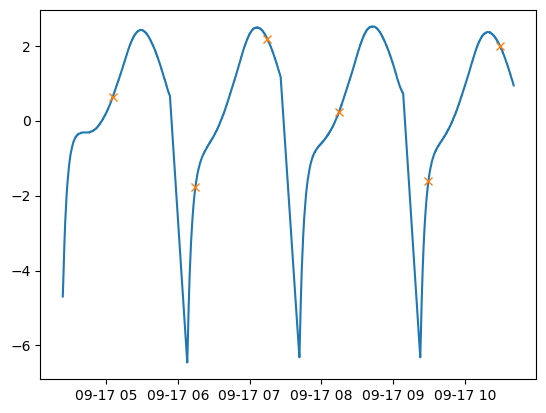

In [107]:
plt.plot(hk_ts.time.to_datetime(), hk_ts['dib_temp'])
plt.plot(x.to_datetime(), dib_temps, 'x')

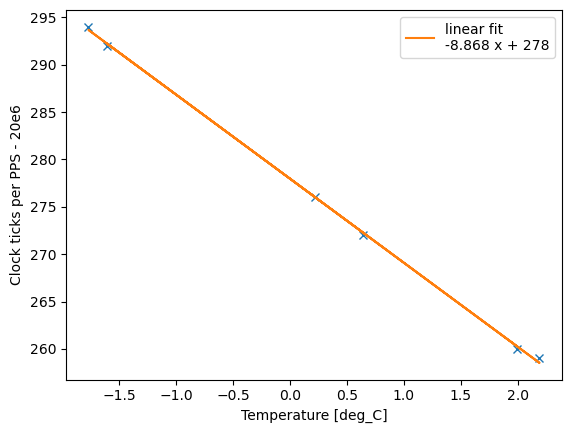

In [136]:
y = cmd_ts[cmd_ts['name'] == 'time_last1sec_count']['value']
x = dib_temps.value
plt.plot(x, y - 20e6, 'x')
plt.xlabel('Temperature [deg_C]')
plt.ylabel('Clock ticks per PPS - 20e6')
coefficients = np.polyfit(x, y - 20e6, 1)
fit_func = np.poly1d(coefficients)
plt.plot(x, fit_func(x), label=f'linear fit {str(fit_func)}')
plt.legend()

This suggests that the colder we are the more clock ticks per pps which means our clock is running faster which is the opposite of expected.

Now do all of the registers

In [137]:
ind = cmd_ts['value'] > 10e6
cmd_ts[ind]
x = cmd_ts[ind].time
xp = hk_ts.time
yp = hk_ts['dib_temp']
dib_temps = np.interp(x.jd, xp.jd, yp)

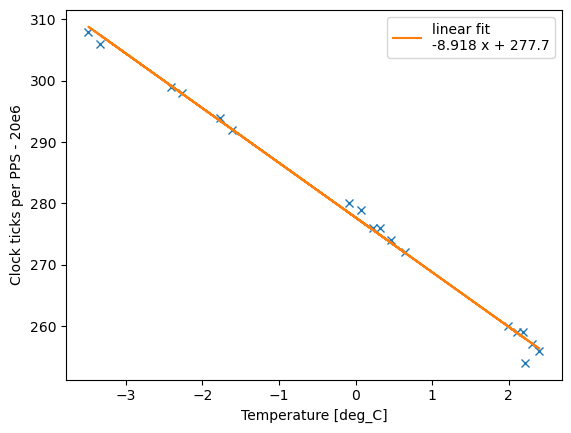

In [138]:
y = cmd_ts[ind]['value']
x = dib_temps.value
plt.plot(x, y - 20e6, 'x')
plt.xlabel('Temperature [deg_C]')
plt.ylabel('Clock ticks per PPS - 20e6')
coefficients = np.polyfit(x, y - 20e6, 1)
fit_func = np.poly1d(coefficients)
plt.plot(x, fit_func(x), label=f'linear fit {str(fit_func)}')
plt.legend()

In [171]:
col1 = np.arange(-40, 20, 5) * u.deg_C
col2 = fit_func(col1.value)
col3 = (1 * u.s / (20e6 + col2) ).to('us')
col4 = (.05 * u.us - col3) / (0.05 * u.us) * 100 * u.percent
col4 
tbl = QTable(data={'Dib Temperature': col1, 'Num clock ticks per pps':col2, 'Time per tick': col3, 'Percent difference': col4})
for this_col in tbl.colnames:
    tbl[this_col].info.format = '%.6f'
tbl

Dib Temperature,Num clock ticks per pps,Time per tick,Percent difference
deg_C,,us,%
float64,float64,float64,float64
-40.000000,634.395026,0.049998,0.003172
-35.000000,589.807329,0.049999,0.002949
-30.000000,545.219631,0.049999,0.002726
-25.000000,500.631934,0.049999,0.002503
-20.000000,456.044237,0.049999,0.002280
-15.000000,411.456539,0.049999,0.002057
-10.000000,366.868842,0.049999,0.001834
-5.000000,322.281144,0.049999,0.001611


In [ ]:
average_clock_ticks_per_pps = np.mean(cmd_ts[ind]['value'])
average_clock_ticks_per_pps
percent_diff = np.abs((20e6 - average_clock_ticks_per_pps) / 20e6) * 100 * u.percent

<Quantity 0.00138861 %>

In [145]:
print(f"The average number of clock ticks per pps is {average_clock_ticks_per_pps}")

The average number of clock ticks per pps is 20000277.722222224


In [146]:
print(f"The difference with the expected number of ticks is {average_clock_ticks_per_pps - 20e6}")

The difference with the expected number of ticks is 277.7222222238779


In [147]:
print(f"The percent difference is {percent_diff}")

The percent difference is 0.0013886111111193896 %


In [148]:
print(f"This means the time between each tick is {(1 * u.s / average_clock_ticks_per_pps).to('us')}")

This means the time between each tick is 0.049999305704085506 us
